# Full interaction (Heisenberg + RKKY)

In [3]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice
using MX2RKKY.observables

using LinearAlgebra: norm
using Random: MersenneTwister
using Statistics: mean, std
using HDF5

using PyPlot; const plt = PyPlot;

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


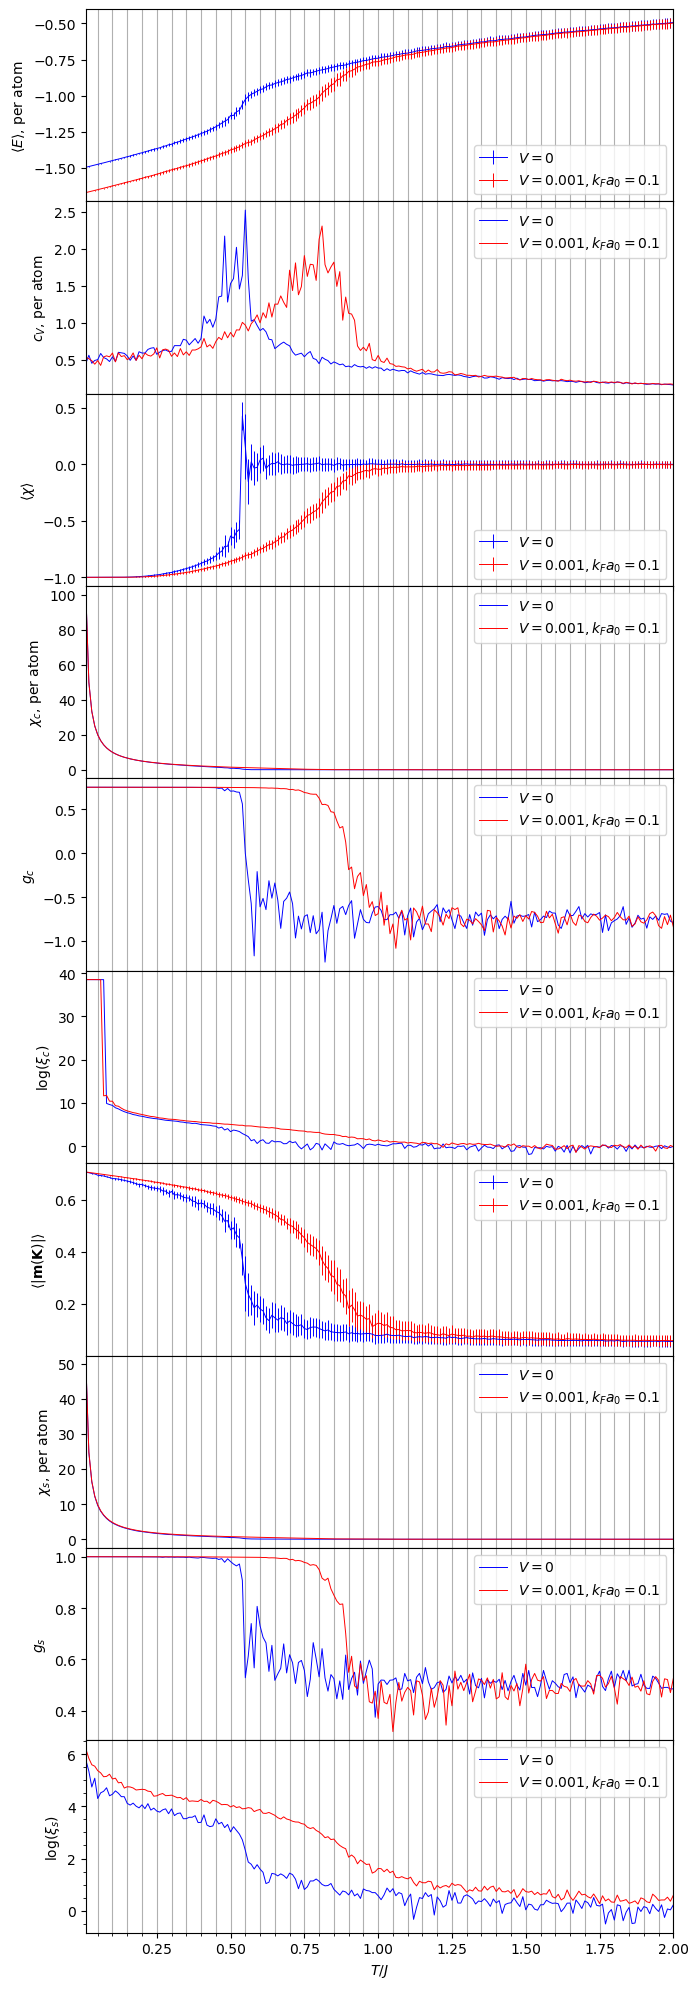

In [21]:
L = 24

fig = plt.figure(figsize=(7, 20))
let gs = plt.matplotlib.gridspec.GridSpec(10, 1, hspace=0), i = 1, ax = plt.subplot(gs[1])
    global add_plot_panel
    function add_plot_panel(;xticks=false)
        if i > 1
            ax = plt.subplot(gs[i], sharex=ax)
        end
        ax.grid(axis="x", which="both")
        if !xticks
            plt.setp(ax.get_xticklabels(), visible=false)
        end
        i += 1
        return ax
    end
end

collect_from_h5(ar, name) = [ar["/T$(T)/$(name)"][] for T in ar["params/T_range"][]]

h5open("../../RKKY_temperature_scan/RKKY_T_scan_L$(L).h5", "r") do ar
    params = read(ar, "params")
    global T_range = collect(params["T_range"])
    global β_range = 1.0 ./ T_range
    global E = collect_from_h5(ar, "E")
    global χ = collect_from_h5(ar, "chi")
    global χ_at_q_min = collect_from_h5(ar, "chi_at_q_min")
    global m_at_K = collect_from_h5(ar, "m_at_K")
    global m_abs_at_K = [mapslices(norm, m, dims=(1,)) for m in m_at_K]
    global m_at_K_q_min = collect_from_h5(ar, "m_at_K_q_min")
    
    V = params["Vpar"]
    lambda = params["lambda"]
    global rkky_label = "\$V=$(V), k_F a_0 = $(lambda)\$"
end

h5open("../../RKKY_temperature_scan/RKKY_T_scan_no_rkky_L$(L).h5", "r") do ar
    global E0 = collect_from_h5(ar, "E")
    global χ0 = collect_from_h5(ar, "chi")
    global χ0_at_q_min = collect_from_h5(ar, "chi_at_q_min")
    global m0_at_K = collect_from_h5(ar, "m_at_K")
    global m0_abs_at_K = [mapslices(norm, m, dims=(1,)) for m in m0_at_K]
    global m0_at_K_q_min = collect_from_h5(ar, "m_at_K_q_min")
end

# Energy
ax = add_plot_panel()
ax.errorbar(T_range, avg_energy.(E0) / L^2, yerr=var_energy.(E0) / L^2, lw=0.7, color="blue", label=raw"$V=0$")
ax.errorbar(T_range, avg_energy.(E) / L^2, yerr=var_energy.(E) / L^2, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\langle E\rangle$, per atom")
ax.legend(loc="lower right")

# Specific heat
ax = add_plot_panel()
ax.plot(T_range, specific_heat.(E0, β_range) / L^2, lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(T_range, specific_heat.(E, β_range) / L^2, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$c_V$, per atom")
ax.legend(loc="upper right")

# Average chirality
ax = add_plot_panel()
ax.errorbar(T_range, avg_chirality.(χ0), var_chirality.(χ0), lw=0.7, color="blue", label=raw"$V=0$")
ax.errorbar(T_range, avg_chirality.(χ), var_chirality.(χ), lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\langle\chi\rangle$")
ax.legend(loc="lower right")

# Chirality susceptibility
ax = add_plot_panel()
ax.plot(T_range, susc_chirality.(χ0, L^2, β_range) / L^2, lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(T_range, susc_chirality.(χ, L^2, β_range) / L^2, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\chi_c$, per atom")
ax.legend(loc="upper right")

# Chirality Binder cumulant
ax = add_plot_panel()
ax.plot(T_range, binder_chirality.(χ0), lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(T_range, binder_chirality.(χ), lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$g_c$")
ax.legend(loc="upper right")

# Chirality correlation length
ax = add_plot_panel()
ax.plot(T_range, log.(abs.(corr_length_chirality.(χ0, χ0_at_q_min, L))), lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(T_range, log.(abs.(corr_length_chirality.(χ, χ_at_q_min, L))), lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\log(\xi_c)$")
ax.legend(loc="upper right")

# Average magnetization at K-point
ax = add_plot_panel()
ax.errorbar(T_range, mean.(m0_abs_at_K), std.(m0_abs_at_K), lw=0.7, color="blue", label=raw"$V=0$")
ax.errorbar(T_range, mean.(m_abs_at_K), std.(m_abs_at_K), lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\langle|\mathbf{m}(\mathbf{K})|\rangle$")
ax.legend(loc="upper right")

# Magnetization at K-point: susceptibility
ax = add_plot_panel()
ax.plot(T_range, susc_spin_K.(m0_at_K, L^2, β_range) / L^2, lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(T_range, susc_spin_K.(m_at_K, L^2, β_range) / L^2, lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\chi_s$, per atom")
ax.legend(loc="upper right")

# Magnetization at K-point: Binder cumulant
ax = add_plot_panel()
ax.plot(T_range, binder_spin_K.(m0_at_K), lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(T_range, binder_spin_K.(m_at_K), lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$g_s$")
ax.legend(loc="upper right")

# Magnetization at K-point: Correlation length
ax = add_plot_panel(xticks=true)
ax.plot(T_range, log.(abs.(corr_length_spin_K.(m0_at_K, m0_at_K_q_min, L))), lw=0.7, color="blue", label=raw"$V=0$")
ax.plot(T_range, log.(abs.(corr_length_spin_K.(m_at_K, m_at_K_q_min, L))), lw=0.7, color="red", label=rkky_label)
ax.set_ylabel(raw"$\log(\xi_s)$")
ax.legend(loc="upper right")

# General plot setup
ax.set_xlim((first(T_range), last(T_range)))
ax.set_xlabel(raw"$T/J$")
ax.minorticks_on()
plt.tight_layout()
plt.show()
fig.savefig("rkky_temp_scan.pdf")